In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
import torchvision.models as models
import numpy as np
import nltk
import gensim.models
from gensim.models import KeyedVectors
import re
from typing import List, Dict
import matplotlib.pyplot as plt

nltk.download('punkt', quiet=True)

True

In [2]:

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

Using device: cuda


In [3]:
print("\nLoading Word2Vec model...")
gn_vec_path = ".\GoogleNews-vectors-negative300.bin.gz"
w2v_model = KeyedVectors.load_word2vec_format(gn_vec_path, binary=True)
print(f"Word2Vec loaded. Vocabulary size: {len(w2v_model.key_to_index)}")


Loading Word2Vec model...
Word2Vec loaded. Vocabulary size: 3000000


In [4]:
def get_word_vector(word):
    """Get vector for a single word"""
    try:
        return torch.tensor(w2v_model[word], dtype=torch.float32)
    except:
        return torch.zeros(300, dtype=torch.float32)

In [5]:
def preprocess_caption(caption) :
    """Clean and tokenize a caption"""
    caption = caption.lower()
    caption = re.sub(r'[^a-z0-9\s\']', '', caption)
    tokens = nltk.tokenize.word_tokenize(caption)
    tokens = [token for token in tokens if token.strip() and token not in ["'", '"', "''", "``"]]
    return tokens

In [6]:
def build_vocabulary(captions_list, min_freq=1):
    """Build word to index mapping"""
    word_counts = {}
    for caption in captions_list:
        tokens = preprocess_caption(caption)
        for token in tokens:
            word_counts[token] = word_counts.get(token, 0) + 1
    
    word_to_idx = {'<pad>': 0, '<start>': 1, '<end>': 2, '<unk>': 3}
    idx_to_word = {0: '<pad>', 1: '<start>', 2: '<end>', 3: '<unk>'}
    
    idx = 4
    for word, count in word_counts.items():
        if count >= min_freq:
            word_to_idx[word] = idx
            idx_to_word[idx] = word
            idx += 1
    
    return word_to_idx, idx_to_word

In [7]:
def caption_to_embeddings(caption, max_len=20):
    
    tokens = preprocess_caption(caption)
    
    # Get embeddings for each token
    embeddings = []
    for token in tokens[:max_len]:  # Truncate if too long
        embeddings.append(get_word_vector(token))
    
    # Pad if too short
    while len(embeddings) < max_len:
        embeddings.append(torch.zeros(300))
    
    return torch.stack(embeddings)  # (max_len, 300)

In [8]:
def caption_to_indices(caption, word_to_idx, max_len=20):
    """Convert caption to token indices"""
    tokens = preprocess_caption(caption)
    indices = [word_to_idx.get(t, word_to_idx['<unk>']) for t in tokens]
    indices = [word_to_idx['<start>']] + indices + [word_to_idx['<end>']]
    
    if len(indices) > max_len:
        indices = indices[:max_len]
    else:
        indices += [word_to_idx['<pad>']] * (max_len - len(indices))
    
    return torch.tensor(indices)

In [9]:
print("\nLoading dataset...")
data = torch.load('flickr8k_dataset_raw.pt', weights_only=False)

images = data['images']
short_captions = data['short_captions']
train_indices = data['train_indices']
val_indices = data['val_indices']
test_indices = data['test_indices']

# Build vocabulary
word_to_idx, idx_to_word = build_vocabulary(short_captions,1)
vocab_size = len(word_to_idx)
print(f"Vocabulary size: {vocab_size}")


Loading dataset...
Vocabulary size: 3812


In [10]:
class CaptionIndexDataset(torch.utils.data.Dataset):
    def __init__(self, images, captions, indices, word_to_idx, max_len=20):
        self.images = images[indices]
        self.captions = [captions[i] for i in indices]
        self.word_to_idx = word_to_idx
        self.max_len = max_len
    
    def __len__(self):
        return len(self.images)
    
    def __getitem__(self, idx):
        return {
            'image': self.images[idx],
            'caption_indices': caption_to_indices(self.captions[idx], self.word_to_idx, self.max_len)
        }

In [11]:
max_seq_len = 20
train_dataset = CaptionIndexDataset(images, short_captions, train_indices, word_to_idx, max_seq_len)
val_dataset = CaptionIndexDataset(images, short_captions, val_indices, word_to_idx, max_seq_len)
test_dataset = CaptionIndexDataset(images, short_captions, test_indices, word_to_idx, max_seq_len)

batch_size = 64
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

In [12]:
class ImageCaptioningModel(nn.Module):
    def __init__(self, vocab_size, embedding_dim=300, hidden_dim=512):
        super().__init__()
        
        # Image encoder
        self.encoder = models.resnet18(pretrained=True)
        for param in self.encoder.parameters():
            param.requires_grad = False
        in_features = self.encoder.fc.in_features
        self.encoder.fc = nn.Identity()
        self.image_projection = nn.Linear(in_features, hidden_dim)
        
        # Word embedding (initialize with Word2Vec!)
        self.word_embedding = nn.Embedding(vocab_size, embedding_dim)
        self.init_embeddings_with_word2vec()
        
        # LSTM decoder
        self.lstm = nn.LSTM(embedding_dim, hidden_dim, batch_first=True, num_layers=2, dropout=0.3)
        
        # Output layer (predict next word)
        self.output_layer = nn.Sequential(
            nn.Linear(hidden_dim, 512),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(512, vocab_size)
        )
        
    def init_embeddings_with_word2vec(self):
        """Initialize embedding layer with pretrained Word2Vec vectors"""
        print("Initializing embeddings with Word2Vec...")
        initialized = 0
        for word, idx in word_to_idx.items():
            if word in w2v_model:
                self.word_embedding.weight.data[idx] = torch.tensor(w2v_model[word])
                initialized += 1
        print(f"Initialized {initialized}/{len(word_to_idx)} words with Word2Vec")
        
        # Option: Freeze or unfreeze embeddings
        self.word_embedding.weight.requires_grad = False  # Freeze Word2Vec
    
    def forward(self, images, target_indices, teacher_forcing_ratio=0.5):
        """
        Args:
            images: (batch, 3, 224, 224)
            target_indices: (batch, seq_len)
        """
        batch_size = images.size(0)
        seq_len = target_indices.size(1)
        
        # Encode image
        image_features = self.encoder(images)
        image_features = self.image_projection(image_features)
        
        # Initialize LSTM with image features
        h0 = image_features.unsqueeze(0).repeat(2, 1, 1)
        c0 = torch.zeros_like(h0)
        
        outputs = []
        current_input = None
        
        for t in range(seq_len):
            if t == 0:
                # First token: start token
                start_tokens = torch.full((batch_size, 1), word_to_idx['<start>']).to(images.device)
                current_input = self.word_embedding(start_tokens)
            else:
                if teacher_forcing_ratio > 0 and torch.rand(1).item() < teacher_forcing_ratio:
                    # Teacher forcing: use ground truth
                    current_input = self.word_embedding(target_indices[:, t-1:t])
                else:
                    # Use previous prediction
                    prev_pred = torch.argmax(outputs[-1], dim=-1, keepdim=True)
                    current_input = self.word_embedding(prev_pred)
            
            # LSTM
            lstm_out, (h0, c0) = self.lstm(current_input, (h0, c0))
            
            # Predict next word
            output = self.output_layer(lstm_out.squeeze(1))
            outputs.append(output)
        
        return torch.stack(outputs, dim=1)  # (batch, seq_len, vocab_size)
    
    def generate(self, images, max_len=20):
        """Generate caption indices"""
        self.eval()
        with torch.no_grad():
            batch_size = images.size(0)
            
            image_features = self.encoder(images)
            image_features = self.image_projection(image_features)
            
            h0 = image_features.unsqueeze(0).repeat(2, 1, 1)
            c0 = torch.zeros_like(h0)
            
            generated_indices = []
            current_input = self.word_embedding(
                torch.full((batch_size, 1), word_to_idx['<start>']).to(images.device)
            )
            
            for _ in range(max_len):
                lstm_out, (h0, c0) = self.lstm(current_input, (h0, c0))
                output = self.output_layer(lstm_out.squeeze(1))
                next_word = torch.argmax(output, dim=-1, keepdim=True)
                generated_indices.append(next_word)
                current_input = self.word_embedding(next_word)
                
                # Stop if all sequences generated <end>
                if (next_word == word_to_idx['<end>']).all():
                    break
            
            return torch.cat(generated_indices, dim=1)

In [13]:
model = ImageCaptioningModel(vocab_size, embedding_dim=300, hidden_dim=512)
model = model.to(device)

c:\Users\Prashant  Mishra\miniconda3\envs\my_env\lib\site-packages\torchvision\models\_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
c:\Users\Prashant  Mishra\miniconda3\envs\my_env\lib\site-packages\torchvision\models\_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet18_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet18_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Initializing embeddings with Word2Vec...
Initialized 3626/3812 words with Word2Vec


In [14]:
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"\nTotal parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")


Total parameters: 18,569,300
Trainable parameters: 6,249,188


In [15]:
criterion = nn.CrossEntropyLoss(ignore_index=word_to_idx['<pad>'])
optimizer = optim.Adam(model.parameters(), lr=0.001)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, patience=3, factor=0.5)


In [16]:
num_epochs = 20
train_losses = []
val_losses = []

print("\n" + "="*50)
print("STARTING TRAINING (CrossEntropy Loss)")
print("="*50)

for epoch in range(num_epochs):
    # Training
    model.train()
    train_loss = 0
    
    for batch in train_loader:
        images = batch['image'].to(device)
        target_indices = batch['caption_indices'].to(device)
        
        # Forward pass
        outputs = model(images, target_indices, teacher_forcing_ratio=0.5)
        
        # Calculate loss (CrossEntropy)
        loss = criterion(outputs.permute(0, 2, 1), target_indices)
        
        # Backward
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        
        train_loss += loss.item()
    
    # Validation
    model.eval()
    val_loss = 0
    
    with torch.no_grad():
        for batch in val_loader:
            images = batch['image'].to(device)
            target_indices = batch['caption_indices'].to(device)
            
            outputs = model(images, target_indices, teacher_forcing_ratio=0)
            loss = criterion(outputs.permute(0, 2, 1), target_indices)
            val_loss += loss.item()
    
    train_loss_avg = train_loss / len(train_loader)
    val_loss_avg = val_loss / len(val_loader)
    
    train_losses.append(train_loss_avg)
    val_losses.append(val_loss_avg)
    
    scheduler.step(val_loss_avg)
    
    print(f"Epoch [{epoch+1}/{num_epochs}] - Train Loss: {train_loss_avg:.4f}, Val Loss: {val_loss_avg:.4f}")


STARTING TRAINING (CrossEntropy Loss)
Epoch [1/20] - Train Loss: 4.4083, Val Loss: 4.2181
Epoch [2/20] - Train Loss: 3.9884, Val Loss: 4.2574
Epoch [3/20] - Train Loss: 3.8502, Val Loss: 4.2106
Epoch [4/20] - Train Loss: 3.7712, Val Loss: 4.2291
Epoch [5/20] - Train Loss: 3.6743, Val Loss: 4.1577
Epoch [6/20] - Train Loss: 3.5813, Val Loss: 4.0974
Epoch [7/20] - Train Loss: 3.4695, Val Loss: 4.0600
Epoch [8/20] - Train Loss: 3.3999, Val Loss: 4.0662
Epoch [9/20] - Train Loss: 3.3117, Val Loss: 4.0637
Epoch [10/20] - Train Loss: 3.2164, Val Loss: 3.9543
Epoch [11/20] - Train Loss: 3.1560, Val Loss: 3.9508
Epoch [12/20] - Train Loss: 3.1267, Val Loss: 3.9054
Epoch [13/20] - Train Loss: 3.0219, Val Loss: 3.9333
Epoch [14/20] - Train Loss: 2.9864, Val Loss: 3.8938
Epoch [15/20] - Train Loss: 2.9396, Val Loss: 3.9390
Epoch [16/20] - Train Loss: 2.9073, Val Loss: 3.8121
Epoch [17/20] - Train Loss: 2.8335, Val Loss: 3.7972
Epoch [18/20] - Train Loss: 2.7867, Val Loss: 3.8671
Epoch [19/20] - 

In [17]:
import os
model_checkpoint = {
    'model_state_dict': model.state_dict(),
    'optimizer_state_dict': optimizer.state_dict(),
    'word_to_idx': word_to_idx,
    'idx_to_word': idx_to_word,
    'vocab_size': vocab_size,
    'train_losses': train_losses,
    'val_losses': val_losses,
    'model_config': {
        'embedding_dim': 300,
        'hidden_dim': 512,
        'max_seq_len': max_seq_len
    }
}

# Save locally
torch.save(model_checkpoint, 'image_captioning_model.pt')
print(f"\n✅ Model saved to 'image_captioning_model.pt'")
print(f"File size: {os.path.getsize('image_captioning_model.pt') / 1e6:.1f} MB")


✅ Model saved to 'image_captioning_model.pt'
File size: 124.5 MB


In [18]:
print("\n" + "="*50)
print("TESTING")
print("="*50)

model.eval()
test_loss = 0

with torch.no_grad():
    for batch in test_loader:
        images = batch['image'].to(device)
        target_indices = batch['caption_indices'].to(device)
        
        outputs = model(images, target_indices, teacher_forcing_ratio=0)
        loss = criterion(outputs.permute(0, 2, 1), target_indices)
        test_loss += loss.item()

test_loss_avg = test_loss / len(test_loader)
print(f"Test Loss (CrossEntropy): {test_loss_avg:.4f}")


TESTING
Test Loss (CrossEntropy): 3.8278


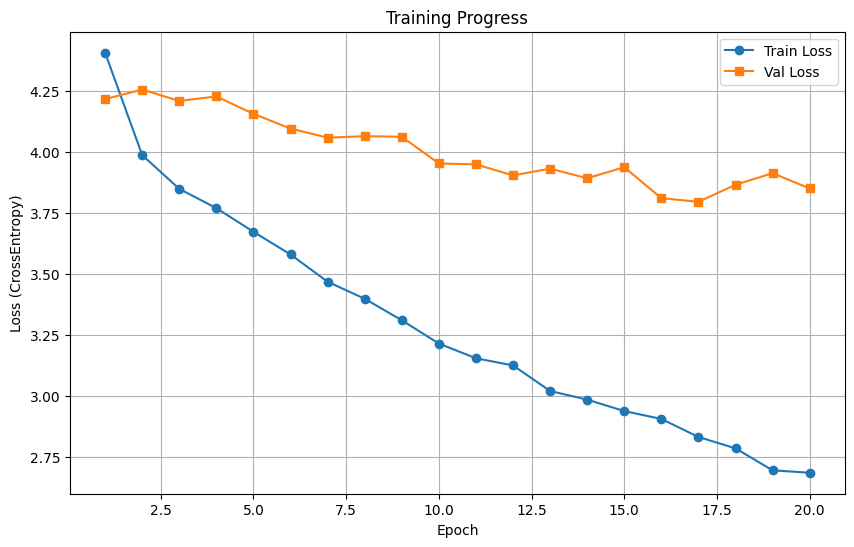

In [19]:
fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(range(1, num_epochs+1), train_losses, label='Train Loss', marker='o')
ax.plot(range(1, num_epochs+1), val_losses, label='Val Loss', marker='s')
ax.set_xlabel('Epoch')
ax.set_ylabel('Loss (CrossEntropy)')
ax.set_title('Training Progress')
ax.legend()
ax.grid(True)
plt.show()